version     machine_id  code_version
after fix   kenza-mba   305b687         35
before fix  neil-mac    f6f773e         35
dtype: int64 

       version  n_keys    median_ms  resizes
0    after fix    1000     0.694500      8.0
1    after fix    2000     1.431083      9.0
2    after fix    5000     3.127459     10.0
3    after fix   10000     6.206041     11.0
4    after fix   30000    26.299500     13.0
5    after fix   60000    55.512500     14.0
6    after fix  114000    84.541292     14.0
7   before fix    1000     0.589500      2.0
8   before fix    2000     1.151250      3.0
9   before fix    5000     4.459166      6.0
10  before fix   10000    16.353792     13.0
11  before fix   30000   120.725791     37.0
12  before fix   60000   503.747750     68.0
13  before fix  114000  1629.164459    117.0 

after fix: slope = 1.05
before fix: slope = 1.72


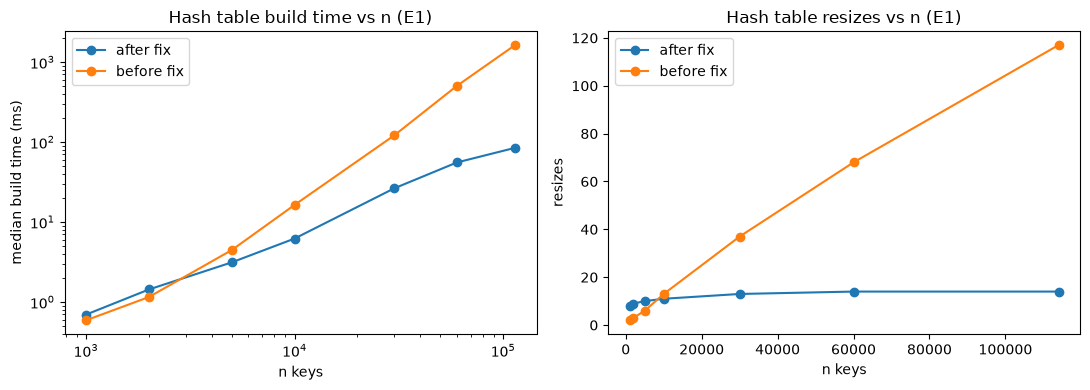

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/project/results/timings.csv")
h = df[(df.experiment == "E1_build_track_id") & (df.index_type == "hash_table")].copy()

FIX = "305b687"
h["version"] = np.where(h.code_version.astype(str).str.startswith(FIX), "after fix", "before fix")

# which rows we're using
print(h.groupby(["version", "machine_id", "code_version"]).size(), "\n")

summary = (h.groupby(["version", "n_keys"])
             .agg(median_ms=("total_ns", lambda s: s.median() / 1e6),
                  resizes=("resizes", "median"))
             .reset_index())
print(summary, "\n")

# log-log slope of build time vs n (about 1 = O(n), about 2 = O(n^2))
for v, g in summary.groupby("version"):
    slope = np.polyfit(np.log(g.n_keys), np.log(g.median_ms), 1)[0]
    print(f"{v}: slope = {slope:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for v, g in summary.groupby("version"):
    axes[0].loglog(g.n_keys, g.median_ms, marker="o", label=v)
    axes[1].plot(g.n_keys, g.resizes, marker="o", label=v)
axes[0].set(title="Hash table build time vs n (E1)", xlabel="n keys", ylabel="median build time (ms)")
axes[1].set(title="Hash table resizes vs n (E1)", xlabel="n keys", ylabel="resizes")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.savefig("inc02_hash_table_e1.png", dpi=150, bbox_inches="tight")
plt.show()